In [ ]:

print("My first global finance research project!")
print("I am learning Python from zero.")
print(100 + 10)


My first global finance research project!
I am learning Python from zero.
110


In [ ]:
!pip install yfinance pandas

In [ ]:
import yfinance as yf
import pandas as pd

print("Our data tools are ready!")

Our data tools are ready!


In [ ]:
stocks = {
    "India": ["RELIANCe.NS","INFY.NS"],
    "USA": ["MSFT","AAPL"],
    "UK": ["HSBA.L","ULVR.L"],
    "JAPAN": ["7203.T","6758.T"],
    "GERMANY": ["SAP.DE","SIE.DE"],
    "HONG KONG": ["1299.HK","0005.HK"],
}
print("Number of markets:",len(stocks))
print("Number of stocks:",sum(len(tickers)for tickers in stocks.values()))

Number of markets: 6
Number of stocks: 12


In [ ]:
test_data = yf.Ticker("AAPL").history(
    period="5y",
    auto_adjust=True
)

print(test_data.head())


                                 Open        High         Low       Close  \
Date                                                                        
2021-10-25 00:00:00-04:00  145.018150  145.691158  143.984259  144.979141   
2021-10-26 00:00:00-04:00  145.652159  147.124964  145.340033  145.642410   
2021-10-27 00:00:00-04:00  145.681409  146.042292  144.832841  145.183975   
2021-10-28 00:00:00-04:00  146.130122  149.397607  146.032579  148.812393   
2021-10-29 00:00:00-04:00  143.594136  146.247147  142.804088  146.110596   

                              Volume  Dividends  Stock Splits  
Date                                                           
2021-10-25 00:00:00-04:00   50720600        0.0           0.0  
2021-10-26 00:00:00-04:00   60893400        0.0           0.0  
2021-10-27 00:00:00-04:00   56094900        0.0           0.0  
2021-10-28 00:00:00-04:00  100077900        0.0           0.0  
2021-10-29 00:00:00-04:00  124953200        0.0           0.0  


In [ ]:
price_data = {}
download_errors = {}

for country, tickers in stocks.items():
    for ticker in tickers:
        try:
            history = yf.Ticker(ticker).history(
                period="5y",
                interval="1d",
                auto_adjust=True
            )

            if history.empty:
                download_errors[ticker] = "No data returned"
                print("No data:", ticker)
                continue

            price_data[ticker] = history["Close"]
            print("Downloaded:", ticker, "| Rows:", len(history))

        except Exception as error:
            download_errors[ticker] = str(error)
            print("Problem with:", ticker, "|", error)

print("\nDownload process finished.")
print("Stocks downloaded:", len(price_data))
print("Stocks with problems:", len(download_errors))


Downloaded: RELIANCe.NS | Rows: 1236
Downloaded: INFY.NS | Rows: 1236
Downloaded: MSFT | Rows: 1255
Downloaded: AAPL | Rows: 1255
Downloaded: HSBA.L | Rows: 1261
Downloaded: ULVR.L | Rows: 1262
Downloaded: 7203.T | Rows: 1221
Downloaded: 6758.T | Rows: 1221
Downloaded: SAP.DE | Rows: 1275
Downloaded: SIE.DE | Rows: 1275
Downloaded: 1299.HK | Rows: 1229
Downloaded: 0005.HK | Rows: 1229

Download process finished.
Stocks downloaded: 12
Stocks with problems: 0


In [ ]:
prices = pd.concat(price_data, axis=1)

prices.index.name = "Date"

print("Table size:", prices.shape)
display(prices.head())


Table size: (7478, 12)


,RELIANCe.NS,INFY.NS,MSFT,AAPL,HSBA.L,ULVR.L,7203.T,6758.T,SAP.DE,SIE.DE,1299.HK,0005.HK
Date,,,,,,,,,,,,
2021-10-24 15:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,1680.915283,2525.041992,NaN,NaN,NaN,NaN
2021-10-24 16:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,80.75705,34.489208
2021-10-24 18:30:00+00:00,1178.401855,1487.229248,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-10-24 22:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,113.947548,122.179077,NaN,NaN
2021-10-24 23:00:00+00:00,NaN,NaN,NaN,NaN,441.737335,4141.368164,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
print("First date:", prices.index.min())
print("Last date:", prices.index.max())

print("\nAvailable observations per stock:")
print(prices.count())

print("\nMissing values per stock:")
print(prices.isna().sum())


First date: 2021-10-24 15:00:00+00:00
Last date: 2026-10-23 04:00:00+00:00

Available observations per stock:
RELIANCe.NS    1236
INFY.NS        1236
MSFT           1255
AAPL           1255
HSBA.L         1261
ULVR.L         1262
7203.T         1221
6758.T         1221
SAP.DE         1275
SIE.DE         1275
1299.HK        1229
0005.HK        1229
dtype: int64

Missing values per stock:
RELIANCe.NS    6242
INFY.NS        6242
MSFT           6223
AAPL           6223
HSBA.L         6217
ULVR.L         6216
7203.T         6257
6758.T         6257
SAP.DE         6203
SIE.DE         6203
1299.HK        6249
0005.HK        6249
dtype: int64


In [ ]:
prices.to_csv("global_stock_prices.csv")

print("Dataset saved as global_stock_prices.csv")


Dataset saved as global_stock_prices.csv


In [ ]:
from google.colab import files

files.download("global_stock_prices.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
stock = "MSFT"

print(prices[stock].head())


Date
2021-10-24 15:00:00+00:00   NaN
2021-10-24 16:00:00+00:00   NaN
2021-10-24 18:30:00+00:00   NaN
2021-10-24 22:00:00+00:00   NaN
2021-10-24 23:00:00+00:00   NaN
Name: MSFT, dtype: float64


In [ ]:
microsoft_returns = prices[stock].pct_change(fill_method=None)

print(microsoft_returns.head())


Date
2021-10-24 15:00:00+00:00   NaN
2021-10-24 16:00:00+00:00   NaN
2021-10-24 18:30:00+00:00   NaN
2021-10-24 22:00:00+00:00   NaN
2021-10-24 23:00:00+00:00   NaN
Name: MSFT, dtype: float64


In [ ]:
print("1. Table size:")
print(prices.shape)

print("\n2. First five rows:")
display(prices.head())

print("\n3. Number of valid prices in each column:")
print(prices.count())

print("\n4. Missing values in each column:")
print(prices.isna().sum())


1. Table size:
(7478, 12)

2. First five rows:


,RELIANCe.NS,INFY.NS,MSFT,AAPL,HSBA.L,ULVR.L,7203.T,6758.T,SAP.DE,SIE.DE,1299.HK,0005.HK
Date,,,,,,,,,,,,
2021-10-24 15:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,1680.915283,2525.041992,NaN,NaN,NaN,NaN
2021-10-24 16:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,80.75705,34.489208
2021-10-24 18:30:00+00:00,1178.401855,1487.229248,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-10-24 22:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,113.947548,122.179077,NaN,NaN
2021-10-24 23:00:00+00:00,NaN,NaN,NaN,NaN,441.737335,4141.368164,NaN,NaN,NaN,NaN,NaN,NaN



3. Number of valid prices in each column:
RELIANCe.NS    1236
INFY.NS        1236
MSFT           1255
AAPL           1255
HSBA.L         1261
ULVR.L         1262
7203.T         1221
6758.T         1221
SAP.DE         1275
SIE.DE         1275
1299.HK        1229
0005.HK        1229
dtype: int64

4. Missing values in each column:
RELIANCe.NS    6242
INFY.NS        6242
MSFT           6223
AAPL           6223
HSBA.L         6217
ULVR.L         6216
7203.T         6257
6758.T         6257
SAP.DE         6203
SIE.DE         6203
1299.HK        6249
0005.HK        6249
dtype: int64


In [ ]:
# Check the current date index
print("Current index type:", type(prices.index))
print("Current timezone:", prices.index.tz)

# Convert timestamps to UTC, then use calendar dates
prices.index = (
    prices.index
    .tz_convert("UTC")
    .normalize()
    .tz_localize(None)
)

# If a stock has multiple entries on the same date,
# keep its last available price for that date
prices = prices.groupby(level=0).last()

print("Data reorganised by date!")
print("New table size:", prices.shape)

display(prices.head())

Current index type: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>
Current timezone: UTC
Data reorganised by date!
New table size: (1558, 12)


,RELIANCe.NS,INFY.NS,MSFT,AAPL,HSBA.L,ULVR.L,7203.T,6758.T,SAP.DE,SIE.DE,1299.HK,0005.HK
Date,,,,,,,,,,,,
2021-10-24,1178.401855,1487.229248,NaN,NaN,441.737335,4141.368164,1680.915283,2525.041992,113.947548,122.179077,80.757050,34.489208
2021-10-25,1205.237183,1497.026489,295.720764,144.979156,445.825256,4182.467773,1709.844604,2591.718994,116.102371,124.235611,80.135521,35.080036
2021-10-26,1189.996460,1519.213501,297.621002,145.642380,443.382477,4155.781250,1730.570068,2532.772705,115.015747,123.655571,78.848022,35.338524
2021-10-27,1176.952637,1497.202271,310.155090,145.184021,439.095184,4163.251953,1727.115845,2492.186523,116.304955,122.899727,79.513969,34.710773
2021-10-28,1148.713135,1465.437622,311.287506,148.812378,440.191956,4176.062988,1732.728638,2539.536865,115.402512,123.286446,78.004494,34.821556


In [ ]:
print("Valid prices per stock:")
display(prices.count())

print("\nMissing prices per stock:")
display(prices.isna().sum())

print("\nFirst date:", prices.index.min())
print("Last date:", prices.index.max())

Valid prices per stock:


,0
RELIANCe.NS,1236
INFY.NS,1236
MSFT,1255
AAPL,1255
HSBA.L,1261
ULVR.L,1262
7203.T,1221
6758.T,1221
SAP.DE,1275
SIE.DE,1275



Missing prices per stock:


,0
RELIANCe.NS,322
INFY.NS,322
MSFT,303
AAPL,303
HSBA.L,297
ULVR.L,296
7203.T,337
6758.T,337
SAP.DE,283
SIE.DE,283



First date: 2021-10-24 00:00:00
Last date: 2026-10-23 00:00:00


In [ ]:
prices.to_csv("global_stock_prices_cleaned.csv")

print("Cleaned prices saved successfully!")

Cleaned prices saved successfully!


In [ ]:
# Calculate daily percentage returns
daily_returns = prices.pct_change(fill_method=None)

# Convert returns into percentages
daily_returns_percent = daily_returns * 100

print("Daily returns calculated!")
print("Table size:", daily_returns.shape)

display(daily_returns_percent.head(10).round(2))

Daily returns calculated!
Table size: (1558, 12)


,RELIANCe.NS,INFY.NS,MSFT,AAPL,HSBA.L,ULVR.L,7203.T,6758.T,SAP.DE,SIE.DE,1299.HK,0005.HK
Date,,,,,,,,,,,,
2021-10-24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-10-25,2.28,0.66,NaN,NaN,0.93,0.99,1.72,2.64,1.89,1.68,-0.77,1.71
2021-10-26,-1.26,1.48,0.64,0.46,-0.55,-0.64,1.21,-2.27,-0.94,-0.47,-1.61,0.74
2021-10-27,-1.10,-1.45,4.21,-0.31,-0.97,0.18,-0.20,-1.60,1.12,-0.61,0.84,-1.78
2021-10-28,-2.40,-2.12,0.37,2.50,0.25,0.31,0.32,1.90,-0.78,0.31,-1.90,0.32
2021-10-29,NaN,NaN,2.24,-1.82,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-10-31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-11-01,-1.46,-0.13,NaN,NaN,NaN,NaN,-0.10,0.22,0.49,3.03,0.40,0.21
2021-11-02,-0.69,0.27,1.14,0.71,-0.44,0.75,NaN,NaN,1.18,-0.57,-2.44,-0.43


In [ ]:
print("Valid daily returns for each stock:")
display(daily_returns.count())

print("\nMissing daily returns for each stock:")
display(daily_returns.isna().sum())

Valid daily returns for each stock:


,0
RELIANCe.NS,940
INFY.NS,940
MSFT,980
AAPL,980
HSBA.L,1004
ULVR.L,1005
7203.T,950
6758.T,950
SAP.DE,1012
SIE.DE,1012



Missing daily returns for each stock:


,0
RELIANCe.NS,618
INFY.NS,618
MSFT,578
AAPL,578
HSBA.L,554
ULVR.L,553
7203.T,608
6758.T,608
SAP.DE,546
SIE.DE,546


In [ ]:
selected_stocks = ["RELIANCE.NS", "MSFT", "7203.T"]

comparison = daily_returns_percent[selected_stocks]

display(comparison.head(10).round(2))

KeyError: "['RELIANCE.NS'] not in index"

In [ ]:
selected_stocks = ["RELIANCe.NS", "MSFT", "7203.T"]

comparison = daily_returns_percent[selected_stocks]

display(comparison.head(10).round(2))

,RELIANCe.NS,MSFT,7203.T
Date,,,
2021-10-24,NaN,NaN,NaN
2021-10-25,2.28,NaN,1.72
2021-10-26,-1.26,0.64,1.21
2021-10-27,-1.10,4.21,-0.20
2021-10-28,-2.40,0.37,0.32
2021-10-29,NaN,2.24,NaN
2021-10-31,NaN,NaN,NaN
2021-11-01,-1.46,NaN,-0.10
2021-11-02,-0.69,1.14,NaN


In [ ]:
daily_returns_percent.to_csv("global_stock_daily_returns.csv")
print("Daily returns saved successfully!")

Daily returns saved successfully!


In [ ]:
from google.colab import files

files.download("global_stock_prices_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download("global_stock_daily_returns.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
average_daily_returns = daily_returns.mean() * 100

print("Average daily return (%):")
display(average_daily_returns.round(4))

Average daily return (%):


,0
RELIANCe.NS,0.0329
INFY.NS,-0.0228
MSFT,0.0692
AAPL,0.1104
HSBA.L,0.0521
ULVR.L,0.0439
7203.T,0.0877
6758.T,0.1233
SAP.DE,0.0592
SIE.DE,0.0861


In [ ]:
daily_volatility = daily_returns.std() * 100

print("Daily volatility (%):")
display(daily_volatility.round(4))

Daily volatility (%):


,0
RELIANCe.NS,1.3327
INFY.NS,1.6245
MSFT,1.8569
AAPL,1.7888
HSBA.L,1.6175
ULVR.L,1.2152
7203.T,1.9336
6758.T,2.0820
SAP.DE,1.8729
SIE.DE,1.9885


In [ ]:
stock_summary = pd.DataFrame({
    "Average daily return (%)": average_daily_returns,
    "Daily volatility (%)": daily_volatility
})

display(stock_summary.round(4))

,Average daily return (%),Daily volatility (%)
RELIANCe.NS,0.0329,1.3327
INFY.NS,-0.0228,1.6245
MSFT,0.0692,1.8569
AAPL,0.1104,1.7888
HSBA.L,0.0521,1.6175
ULVR.L,0.0439,1.2152
7203.T,0.0877,1.9336
6758.T,0.1233,2.0820
SAP.DE,0.0592,1.8729
SIE.DE,0.0861,1.9885


In [ ]:
display(stock_summary.round(4))

NameError: name 'stock_summary' is not defined

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving global_stock_daily_returns.csv to global_stock_daily_returns.csv
Saving global_stock_prices_cleaned.csv to global_stock_prices_cleaned.csv


In [ ]:
import pandas as pd

prices = pd.read_csv(
    "global_stock_prices_cleaned.csv",
    index_col=0,
    parse_dates=True
)

daily_returns = pd.read_csv(
    "global_stock_daily_returns.csv",
    index_col=0,
    parse_dates=True
)

print("Prices shape:", prices.shape)
print("Daily returns shape:", daily_returns.shape)

display(prices.head())

Prices shape: (1558, 12)
Daily returns shape: (1558, 12)


,RELIANCe.NS,INFY.NS,MSFT,AAPL,HSBA.L,ULVR.L,7203.T,6758.T,SAP.DE,SIE.DE,1299.HK,0005.HK
Date,,,,,,,,,,,,
2021-10-24,1178.401855,1487.229248,NaN,NaN,441.737335,4141.368164,1680.915283,2525.041992,113.947548,122.179077,80.757050,34.489208
2021-10-25,1205.237183,1497.026489,295.720764,144.979156,445.825256,4182.467773,1709.844604,2591.718994,116.102371,124.235611,80.135521,35.080036
2021-10-26,1189.996460,1519.213501,297.621002,145.642380,443.382477,4155.781250,1730.570068,2532.772705,115.015747,123.655571,78.848022,35.338524
2021-10-27,1176.952637,1497.202271,310.155090,145.184021,439.095184,4163.251953,1727.115845,2492.186523,116.304955,122.899727,79.513969,34.710773
2021-10-28,1148.713135,1465.437622,311.287506,148.812378,440.191956,4176.062988,1732.728638,2539.536865,115.402512,123.286446,78.004494,34.821556


In [ ]:
average_daily_returns = daily_returns.mean() * 100
daily_volatility = daily_returns.std() * 100

stock_summary = pd.DataFrame({
    "Average daily return (%)": average_daily_returns,
    "Daily volatility (%)": daily_volatility
})

display(stock_summary.round(4))

,Average daily return (%),Daily volatility (%)
RELIANCe.NS,3.2856,133.2718
INFY.NS,-2.2801,162.4469
MSFT,6.9172,185.6879
AAPL,11.0450,178.8795
HSBA.L,5.2059,161.7459
ULVR.L,4.3889,121.5182
7203.T,8.7692,193.3572
6758.T,12.3338,208.1960
SAP.DE,5.9201,187.2916
SIE.DE,8.6075,198.8455


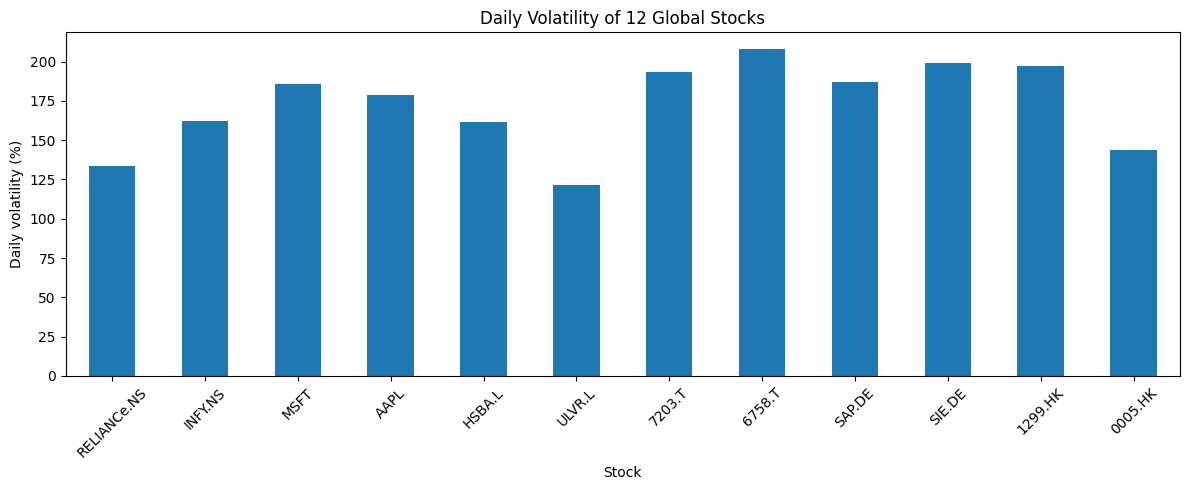

In [ ]:
import matplotlib.pyplot as plt

stock_summary.plot(
    kind="bar",
    y="Daily volatility (%)",
    legend=False,
    figsize=(12, 5)
)

plt.title("Daily Volatility of 12 Global Stocks")
plt.xlabel("Stock")
plt.ylabel("Daily volatility (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
correlation_matrix = daily_returns.corr(min_periods=60)

display(correlation_matrix.round(2))

,RELIANCe.NS,INFY.NS,MSFT,AAPL,HSBA.L,ULVR.L,7203.T,6758.T,SAP.DE,SIE.DE,1299.HK,0005.HK
RELIANCe.NS,1.00,0.24,0.11,0.08,0.10,0.01,0.12,0.10,0.13,0.21,0.12,0.16
INFY.NS,0.24,1.00,0.25,0.25,0.07,0.02,0.13,0.24,0.19,0.18,0.16,0.17
MSFT,0.11,0.25,1.00,0.54,0.04,-0.04,0.13,0.29,0.12,0.09,0.10,0.17
AAPL,0.08,0.25,0.54,1.00,0.11,0.01,0.23,0.38,0.13,0.16,0.17,0.24
HSBA.L,0.10,0.07,0.04,0.11,1.00,0.13,0.18,0.15,0.07,0.25,0.21,0.57
ULVR.L,0.01,0.02,-0.04,0.01,0.13,1.00,0.06,0.02,0.06,-0.02,0.01,0.01
7203.T,0.12,0.13,0.13,0.23,0.18,0.06,1.00,0.51,0.12,0.15,0.11,0.26
6758.T,0.10,0.24,0.29,0.38,0.15,0.02,0.51,1.00,0.17,0.20,0.18,0.24
SAP.DE,0.13,0.19,0.12,0.13,0.07,0.06,0.12,0.17,1.00,0.37,0.01,0.09
SIE.DE,0.21,0.18,0.09,0.16,0.25,-0.02,0.15,0.20,0.37,1.00,0.17,0.19


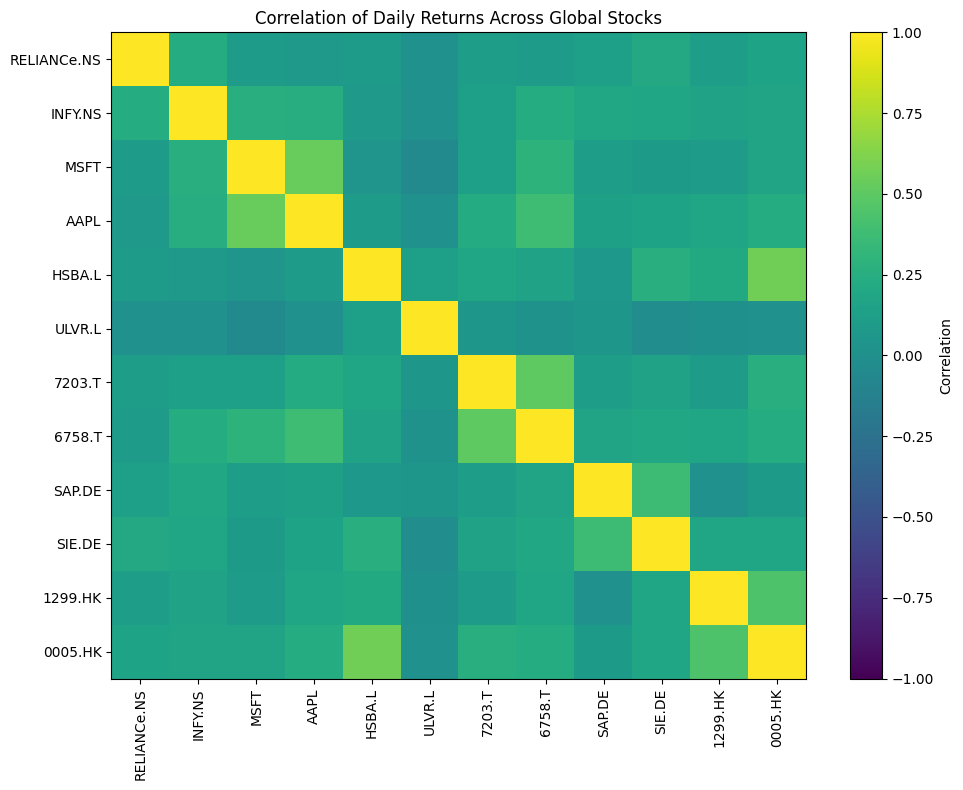

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

plt.imshow(
    correlation_matrix,
    vmin=-1,
    vmax=1,
    aspect="auto"
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation_matrix.index)),
    correlation_matrix.index
)

plt.title("Correlation of Daily Returns Across Global Stocks")
plt.tight_layout()
plt.show()

In [ ]:
### Day 5: Volatility and Correlation Findings

The analysis examined the daily returns of 12 stocks across six international markets.

The daily volatility comparison showed that 6758.T had the highest volatility (2.0820%), while ULVR.L had the lowest (1.2152%).

The correlation analysis found that HSBA.L and 0005.HK had the highest correlation between two different stocks (0.57). MSFT and ULVR.L had the lowest correlation (-0.04), indicating almost no linear relationship in their daily returns over the analysed period.

Most stock pairs showed relatively weak positive correlations. This suggests that combining selected stocks may offer diversification benefits. However, the actual reduction in portfolio risk must be tested through portfolio calculations.

**Limitations:** The analysis uses local-currency returns, and differences in trading calendars and missing observations may affect the comparisons. Further data validation is needed before drawing firm conclusions.

In [ ]:

# STEP 1: Check the quality of our daily returns

print("Total dates:", len(daily_returns))
print("\nMissing returns per stock:")
print(daily_returns.isna().sum())

# Keep dates where all 12 stocks have valid returns
complete_returns = daily_returns.dropna(how="any")

print("\nCommon valid dates:", len(complete_returns))
print("First common date:", complete_returns.index.min())
print("Last common date:", complete_returns.index.max())


Total dates: 1558

Missing returns per stock:
RELIANCe.NS    618
INFY.NS        618
MSFT           578
AAPL           578
HSBA.L         554
ULVR.L         553
7203.T         608
6758.T         608
SAP.DE         546
SIE.DE         546
1299.HK        609
0005.HK        609
dtype: int64

Common valid dates: 563
First common date: 2021-10-26 00:00:00
Last common date: 2026-10-22 00:00:00


In [ ]:

import pandas as pd
import numpy as np

# Use the 563 common dates
# Each of the 12 stocks receives an equal weight
weights = np.repeat(1 / len(complete_returns.columns),
                    len(complete_returns.columns))

# Calculate daily portfolio returns
portfolio_returns = complete_returns.dot(weights)

# Summarise daily and annualised performance
portfolio_summary = pd.DataFrame({
    "Average daily return (%)": [
        portfolio_returns.mean() * 100
    ],
    "Daily volatility (%)": [
        portfolio_returns.std() * 100
    ],
    "Annualised return estimate (%)": [
        portfolio_returns.mean() * 252 * 100
    ],
    "Annualised volatility (%)": [
        portfolio_returns.std() * np.sqrt(252) * 100
    ]
}, index=["Equal-weighted global portfolio"])

display(portfolio_summary.round(3))

print("Number of stocks:", len(complete_returns.columns))
print("Weight per stock:", round(100 / len(complete_returns.columns), 2), "%")
print("Observations:", len(portfolio_returns))


,Average daily return (%),Daily volatility (%),Annualised return estimate (%),Annualised volatility (%)
Equal-weighted global portfolio,8.84,81.961,2227.721,1301.084


Number of stocks: 12
Weight per stock: 8.33 %
Observations: 563


In [ ]:

print("Portfolio daily return statistics:")
print(portfolio_returns.describe())

print("\nFirst 10 portfolio returns:")
print(portfolio_returns.head(10))

print("\nIndividual stock returns on the same dates:")
display((complete_returns.mean() * 100).round(4))

print("\nLargest absolute daily stock returns (%):")
display((complete_returns.abs().max() * 100).round(2))



Portfolio daily return statistics:
count    563.000000
mean       0.088402
std        0.819606
min       -2.866602
25%       -0.367783
50%        0.087031
75%        0.555496
max        3.860623
dtype: float64

First 10 portfolio returns:
Date
2021-10-26   -0.266942
2021-10-27   -0.138304
2021-10-28   -0.076231
2021-11-09   -0.293134
2021-11-10    0.166603
2021-11-11    0.442546
2021-11-16   -0.152117
2021-11-17    0.081827
2021-11-24    0.902376
2021-11-30    1.318732
dtype: float64

Individual stock returns on the same dates:


,0
RELIANCe.NS,9.8469
INFY.NS,-0.6263
MSFT,7.1414
AAPL,11.9307
HSBA.L,6.8616
ULVR.L,1.6595
7203.T,11.6975
6758.T,14.4288
SAP.DE,5.5757
SIE.DE,15.4670



Largest absolute daily stock returns (%):


,0
RELIANCe.NS,601.98
INFY.NS,813.38
MSFT,1550.67
AAPL,889.75
HSBA.L,886.75
ULVR.L,623.15
7203.T,1434.01
6758.T,865.10
SAP.DE,1607.02
SIE.DE,1058.01


In [ ]:

print("DAILY RETURNS: raw values")
print(daily_returns.agg(["min", "mean", "max"]).round(6))

print("\nPRICE DATA: sample values")
display(prices[["MSFT", "AAPL", "SAP.DE"]].head(10))

print("\nPRICE DATA: minimum and maximum")
display(prices[["MSFT", "AAPL", "SAP.DE"]].agg(["min", "max"]))

print("\nDates in ascending order:", prices.index.is_monotonic_increasing)
print("Duplicate dates:", prices.index.duplicated().sum())


DAILY RETURNS: raw values
      RELIANCe.NS   INFY.NS       MSFT       AAPL    HSBA.L    ULVR.L  \
min     -7.485140 -8.133839  -9.993140  -9.245604 -8.867498 -7.276148   
mean     0.032856 -0.022801   0.069172   0.110450  0.052059  0.043889   
max      6.019801  7.934008  15.506739  15.328850  7.944856  9.426395   

         7203.T     6758.T     SAP.DE     SIE.DE    1299.HK   0005.HK  
min   -8.477442 -12.789878 -16.070151  -9.345045 -10.325713 -5.967441  
mean   0.087692   0.123338   0.059201   0.086075   0.008282  0.120249  
max   14.340089  13.517867  10.617851  10.580085   8.786290  5.578812  

PRICE DATA: sample values


,MSFT,AAPL,SAP.DE
Date,,,
2021-10-24,NaN,NaN,113.947548
2021-10-25,295.720764,144.979156,116.102371
2021-10-26,297.621002,145.642380,115.015747
2021-10-27,310.155090,145.184021,116.304955
2021-10-28,311.287506,148.812378,115.402512
2021-10-29,318.264801,146.110596,NaN
2021-10-31,NaN,NaN,116.323372
2021-11-01,316.105286,145.291290,116.894310
2021-11-02,319.713959,146.325165,118.275612



PRICE DATA: minimum and maximum


,MSFT,AAPL,SAP.DE
min,207.343658,122.827606,76.698814
max,543.450012,348.220001,273.153168



Dates in ascending order: True
Duplicate dates: 0


In [ ]:

# Returns are already in percentage points.
# Do NOT multiply by 100 again.

portfolio_summary = pd.DataFrame({
    "Average daily return (%)": [
        portfolio_returns.mean()
    ],
    "Daily volatility (%)": [
        portfolio_returns.std()
    ],
    "Annualised return estimate (%)": [
        portfolio_returns.mean() * 252
    ],
    "Annualised volatility (%)": [
        portfolio_returns.std() * np.sqrt(252)
    ]
}, index=["Equal-weighted global portfolio"])

display(portfolio_summary.round(3))


,Average daily return (%),Daily volatility (%),Annualised return estimate (%),Annualised volatility (%)
Equal-weighted global portfolio,0.088,0.82,22.277,13.011


In [ ]:

# Compare the equal-weighted portfolio with individual stocks

individual_summary = pd.DataFrame({
    "Average daily return (%)": complete_returns.mean(),
    "Daily volatility (%)": complete_returns.std()
})

portfolio_comparison = pd.concat([
    individual_summary,
    pd.DataFrame({
        "Average daily return (%)": [portfolio_returns.mean()],
        "Daily volatility (%)": [portfolio_returns.std()]
    }, index=["Equal-weighted portfolio"])
])

display(portfolio_comparison.round(4))

print("\nPortfolio volatility:", round(portfolio_returns.std(), 4), "%")
print("Average individual-stock volatility:",
      round(individual_summary["Daily volatility (%)"].mean(), 4), "%")


,Average daily return (%),Daily volatility (%)
RELIANCe.NS,0.0985,1.2840
INFY.NS,-0.0063,1.6650
MSFT,0.0714,1.9279
AAPL,0.1193,1.6350
HSBA.L,0.0686,1.6315
ULVR.L,0.0166,1.1614
7203.T,0.1170,1.9326
6758.T,0.1443,2.0235
SAP.DE,0.0558,2.0177
SIE.DE,0.1547,2.0809



Portfolio volatility: 0.8196 %
Average individual-stock volatility: 1.7249 %


In [ ]:

# Final date-alignment audit

print("Price dates by weekday (0 = Monday, 6 = Sunday):")
print(prices.index.dayofweek.value_counts().sort_index())

print("\nWeekend dates in prices:")
print(prices.index[prices.index.dayofweek >= 5][:15])

print("\nDates with all 12 stock prices:")
print(prices.dropna(how="any").shape[0])

print("\nDates with all 12 daily returns:")
print(daily_returns.dropna(how="any").shape[0])

print("\nAre price dates duplicated?", prices.index.duplicated().any())


Price dates by weekday (0 = Monday, 6 = Sunday):
Date
0    261
1    261
2    261
3    261
4    253
6    261
Name: count, dtype: int64

Weekend dates in prices:
DatetimeIndex(['2021-10-24', '2021-10-31', '2021-11-07', '2021-11-14',
               '2021-11-21', '2021-11-28', '2021-12-05', '2021-12-12',
               '2021-12-19', '2021-12-26', '2022-01-02', '2022-01-09',
               '2022-01-16', '2022-01-23', '2022-01-30'],
              dtype='datetime64[ns]', name='Date', freq=None)

Dates with all 12 stock prices:
859

Dates with all 12 daily returns:
563

Are price dates duplicated? False


In [ ]:

import pandas as pd

original_prices = pd.read_csv("global_stock_prices.csv", index_col=0)

print("Original shape:", original_prices.shape)
print("\nFirst 10 index values:")
print(original_prices.index[:10])

print("\nIndex data type:")
print(original_prices.index.dtype)

print("\nFirst 5 rows:")
display(original_prices.head())


Original shape: (7478, 12)

First 10 index values:
Index(['2021-10-24 15:00:00+00:00', '2021-10-24 16:00:00+00:00',
       '2021-10-24 18:30:00+00:00', '2021-10-24 22:00:00+00:00',
       '2021-10-24 23:00:00+00:00', '2021-10-25 04:00:00+00:00',
       '2021-10-25 15:00:00+00:00', '2021-10-25 16:00:00+00:00',
       '2021-10-25 18:30:00+00:00', '2021-10-25 22:00:00+00:00'],
      dtype='object', name='Date')

Index data type:
object

First 5 rows:


,RELIANCe.NS,INFY.NS,MSFT,AAPL,HSBA.L,ULVR.L,7203.T,6758.T,SAP.DE,SIE.DE,1299.HK,0005.HK
Date,,,,,,,,,,,,
2021-10-24 15:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,1680.915283,2525.041992,NaN,NaN,NaN,NaN
2021-10-24 16:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,80.75705,34.489208
2021-10-24 18:30:00+00:00,1178.401855,1487.229248,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-10-24 22:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,113.947548,122.179077,NaN,NaN
2021-10-24 23:00:00+00:00,NaN,NaN,NaN,NaN,441.737335,4141.368164,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:

import pandas as pd

# Reload the original data without changing the saved CSV
original_prices = pd.read_csv("global_stock_prices.csv", index_col=0)

# Parse the UTC timestamps
original_prices.index = pd.to_datetime(
    original_prices.index,
    utc=True
)

# Convert each timestamp to its original market's local calendar date
# based on the timestamp's UTC time and each exchange's timezone.
market_timezones = {
    "RELIANCe.NS": "Asia/Kolkata",
    "INFY.NS": "Asia/Kolkata",
    "MSFT": "America/New_York",
    "AAPL": "America/New_York",
    "HSBA.L": "Europe/London",
    "ULVR.L": "Europe/London",
    "7203.T": "Asia/Tokyo",
    "6758.T": "Asia/Tokyo",
    "SAP.DE": "Europe/Berlin",
    "SIE.DE": "Europe/Berlin",
    "1299.HK": "Asia/Hong_Kong",
    "0005.HK": "Asia/Hong_Kong"
}

# Create one date-indexed series per stock using its local timezone.
# Keep the last available price if multiple rows map to the same local date.
local_series = []

for ticker in original_prices.columns:
    local_dates = (
        original_prices.index
        .tz_convert(market_timezones[ticker])
        .tz_localize(None)
        .normalize()
    )

    series = original_prices[ticker].copy()
    series.index = local_dates
    series = series.groupby(level=0).last()
    series.name = ticker
    local_series.append(series)

corrected_prices = pd.concat(local_series, axis=1).sort_index()

print("Corrected candidate shape:", corrected_prices.shape)
print("\nWeekday counts (0 = Monday, 6 = Sunday):")
print(corrected_prices.index.dayofweek.value_counts().sort_index())
print("\nFirst dates:")
print(corrected_prices.index[:10])


Corrected candidate shape: (1567, 12)

Weekday counts (0 = Monday, 6 = Sunday):
Date
0    261
1    261
2    261
3    261
4    261
5      1
6    261
Name: count, dtype: int64

First dates:
DatetimeIndex(['2021-10-24', '2021-10-25', '2021-10-26', '2021-10-27',
               '2021-10-28', '2021-10-29', '2021-10-31', '2021-11-01',
               '2021-11-02', '2021-11-03'],
              dtype='datetime64[ns]', name='Date', freq=None)


In [ ]:
import pandas as pd

original_prices = pd.read_csv("global_stock_prices.csv", index_col=0)
original_prices.index = pd.to_datetime(original_prices.index, utc=True)

market_timezones = {
    "RELIANCe.NS": "Asia/Kolkata",
    "INFY.NS": "Asia/Kolkata",
    "MSFT": "America/New_York",
    "AAPL": "America/New_York",
    "HSBA.L": "Europe/London",
    "ULVR.L": "Europe/London",
    "7203.T": "Asia/Tokyo",
    "6758.T": "Asia/Tokyo",
    "SAP.DE": "Europe/Berlin",
    "SIE.DE": "Europe/Berlin",
    "1299.HK": "Asia/Hong_Kong",
    "0005.HK": "Asia/Hong_Kong"
}

local_series = []

for ticker in original_prices.columns:
    # Keep only timestamps where this stock has a price
    series = original_prices[ticker].dropna().copy()

    # Convert timestamps to the stock's local market date
    series.index = (
        series.index
        .tz_convert(market_timezones[ticker])
        .tz_localize(None)
        .normalize()
    )

    # Keep one observation per local date
    series = series.groupby(level=0).last()
    series.name = ticker
    local_series.append(series)

corrected_prices = pd.concat(local_series, axis=1).sort_index()

# Remove dates when no stock has a price
corrected_prices = corrected_prices.dropna(how="all")

print("Corrected shape:", corrected_prices.shape)
print("\nWeekday counts (0 = Monday, 6 = Sunday):")
print(corrected_prices.index.dayofweek.value_counts().sort_index())
print("\nFirst 10 dates:")
print(corrected_prices.index[:10])
print("\nMissing prices per stock:")
print(corrected_prices.isna().sum())

Corrected shape: (1306, 12)

Weekday counts (0 = Monday, 6 = Sunday):
Date
0    261
1    261
2    261
3    261
4    261
5      1
Name: count, dtype: int64

First 10 dates:
DatetimeIndex(['2021-10-25', '2021-10-26', '2021-10-27', '2021-10-28',
               '2021-10-29', '2021-11-01', '2021-11-02', '2021-11-03',
               '2021-11-04', '2021-11-05'],
              dtype='datetime64[ns]', name='Date', freq=None)

Missing prices per stock:
RELIANCe.NS    70
INFY.NS        70
MSFT           51
AAPL           51
HSBA.L         45
ULVR.L         44
7203.T         85
6758.T         85
SAP.DE         31
SIE.DE         31
1299.HK        77
0005.HK        77
dtype: int64


In [ ]:
# Find any weekend dates
weekend_dates = corrected_prices[
    corrected_prices.index.dayofweek >= 5
]

print("Weekend rows:")
print(weekend_dates)

# Check whether each stock has duplicate local dates
print("\nDuplicate dates:", corrected_prices.index.duplicated().sum())

# Check the date range
print("\nStart date:", corrected_prices.index.min())
print("End date:", corrected_prices.index.max())

# Check whether any prices are zero or negative
print("\nNon-positive prices:")
print((corrected_prices <= 0).sum())

Weekend rows:
            RELIANCe.NS     INFY.NS  MSFT  AAPL  HSBA.L  ULVR.L  7203.T  \
Date                                                                      
2025-02-01  1253.772461  1760.04895   NaN   NaN     NaN     NaN     NaN   

            6758.T  SAP.DE  SIE.DE  1299.HK  0005.HK  
Date                                                  
2025-02-01     NaN     NaN     NaN      NaN      NaN  

Duplicate dates: 0

Start date: 2021-10-25 00:00:00
End date: 2026-10-23 00:00:00

Non-positive prices:
RELIANCe.NS    0
INFY.NS        0
MSFT           0
AAPL           0
HSBA.L         0
ULVR.L         0
7203.T         0
6758.T         0
SAP.DE         0
SIE.DE         0
1299.HK        0
0005.HK        0
dtype: int64


In [ ]:
# Remove the anomalous weekend date
corrected_prices = corrected_prices[
    corrected_prices.index.dayofweek < 5
].copy()

# Calculate daily percentage returns
daily_returns = corrected_prices.pct_change(fill_method=None) * 100

# Remove rows where any stock's return is missing
complete_returns = daily_returns.dropna(how="any")

print("Price data shape:", corrected_prices.shape)
print("Daily returns shape:", daily_returns.shape)
print("Complete common returns:", complete_returns.shape)

print("\nWeekday counts:")
print(corrected_prices.index.dayofweek.value_counts().sort_index())

print("\nMissing values in complete returns:")
print(complete_returns.isna().sum().sum())

Price data shape: (1305, 12)
Daily returns shape: (1305, 12)
Complete common returns: (861, 12)

Weekday counts:
Date
0    261
1    261
2    261
3    261
4    261
Name: count, dtype: int64

Missing values in complete returns:
0


In [ ]:
import numpy as np
import pandas as pd

# Individual stock statistics on the same 861 dates
stock_summary = pd.DataFrame({
    "Mean daily return (%)": complete_returns.mean(),
    "Daily volatility (%)": complete_returns.std()
})

# Equal-weighted portfolio: 1/12 invested in each stock
weights = np.repeat(1 / len(complete_returns.columns),
                    len(complete_returns.columns))

portfolio_returns = complete_returns.dot(weights)

portfolio_summary = pd.Series({
    "Average daily return (%)": portfolio_returns.mean(),
    "Daily volatility (%)": portfolio_returns.std(),
    "Annualised return estimate (%)": portfolio_returns.mean() * 252,
    "Annualised volatility (%)": portfolio_returns.std() * np.sqrt(252)
})

average_stock_volatility = stock_summary["Daily volatility (%)"].mean()

volatility_reduction = (
    (average_stock_volatility - portfolio_returns.std())
    / average_stock_volatility
) * 100

print("INDIVIDUAL STOCK PERFORMANCE")
print(stock_summary.round(4))

print("\nEQUAL-WEIGHTED PORTFOLIO")
print(portfolio_summary.round(4))

print("\nAverage individual stock daily volatility (%):",
      round(average_stock_volatility, 4))

print("Portfolio volatility reduction (%):",
      round(volatility_reduction, 2))

INDIVIDUAL STOCK PERFORMANCE
             Mean daily return (%)  Daily volatility (%)
RELIANCe.NS                 0.0464                1.3687
INFY.NS                     0.0000                1.6461
MSFT                        0.1032                1.8302
AAPL                        0.0965                1.7755
HSBA.L                      0.0234                1.5810
ULVR.L                      0.0523                1.2046
7203.T                      0.0858                2.0249
6758.T                      0.1165                2.0763
SAP.DE                      0.1011                1.9362
SIE.DE                      0.1023                1.9482
1299.HK                     0.0371                2.0251
0005.HK                     0.0971                1.4678

EQUAL-WEIGHTED PORTFOLIO
Average daily return (%)           0.0718
Daily volatility (%)               0.8160
Annualised return estimate (%)    18.0993
Annualised volatility (%)         12.9542
dtype: float64

Average individual s

In [ ]:
# Save corrected prices and returns
corrected_prices.to_csv("global_stock_prices_corrected.csv")
daily_returns.to_csv("global_stock_daily_returns_corrected.csv")
complete_returns.to_csv("global_stock_common_returns.csv")

# Save individual-stock performance
stock_summary.to_csv("global_stock_performance_summary.csv")

# Save portfolio returns
portfolio_returns.to_csv("equal_weighted_portfolio_returns.csv")

print("Corrected datasets and portfolio results saved successfully!")

Corrected datasets and portfolio results saved successfully!


In [ ]:

import numpy as np
import pandas as pd

# Use the same 861 dates for a fair comparison
returns = complete_returns.copy()

# Equal weights
n = len(returns.columns)
equal_weights = pd.Series(1 / n, index=returns.columns)

# Historical daily volatility for each stock
volatility = returns.std()

# Inverse-volatility weights
inverse_volatility = 1 / volatility
risk_weights = inverse_volatility / inverse_volatility.sum()

# Calculate portfolio returns
equal_portfolio = returns.dot(equal_weights)
risk_weighted_portfolio = returns.dot(risk_weights)

# Compare performance
comparison = pd.DataFrame({
    "Mean daily return (%)": [
        equal_portfolio.mean(),
        risk_weighted_portfolio.mean()
    ],
    "Daily volatility (%)": [
        equal_portfolio.std(),
        risk_weighted_portfolio.std()
    ]
}, index=["Equal-weighted", "Inverse-volatility"])

comparison["Annualised return estimate (%)"] = (
    comparison["Mean daily return (%)"] * 252
)

comparison["Annualised volatility (%)"] = (
    comparison["Daily volatility (%)"] * np.sqrt(252)
)

print("PORTFOLIO COMPARISON")
print(comparison.round(4))

print("\nINVERSE-VOLATILITY WEIGHTS (%)")
print((risk_weights * 100).round(2).sort_values(ascending=False))


PORTFOLIO COMPARISON
                    Mean daily return (%)  Daily volatility (%)  \
Equal-weighted                     0.0718                0.8160   
Inverse-volatility                 0.0692                0.7776   

                    Annualised return estimate (%)  Annualised volatility (%)  
Equal-weighted                             18.0993                    12.9542  
Inverse-volatility                         17.4365                    12.3440  

INVERSE-VOLATILITY WEIGHTS (%)
ULVR.L         11.71
RELIANCe.NS    10.30
0005.HK         9.61
HSBA.L          8.92
INFY.NS         8.57
AAPL            7.94
MSFT            7.71
SAP.DE          7.28
SIE.DE          7.24
7203.T          6.96
1299.HK         6.96
6758.T          6.79
dtype: float64


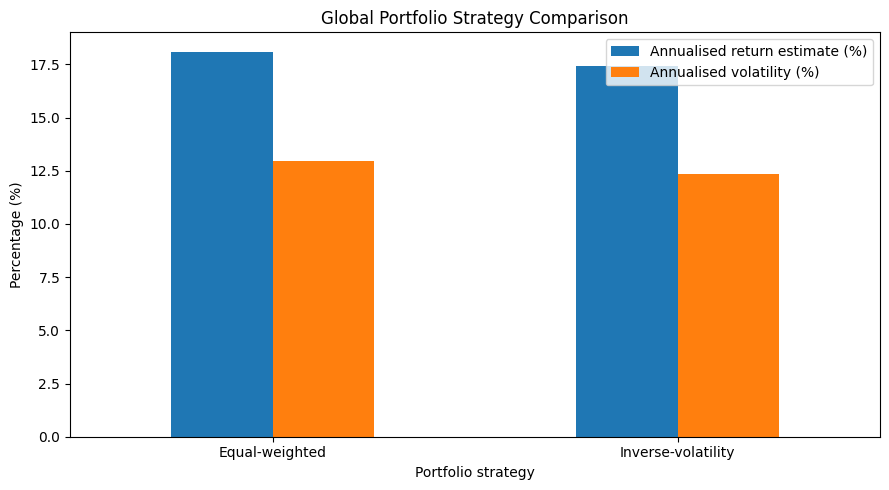

In [ ]:

import matplotlib.pyplot as plt

comparison[[
    "Annualised return estimate (%)",
    "Annualised volatility (%)"
]].plot(kind="bar", figsize=(9, 5))

plt.title("Global Portfolio Strategy Comparison")
plt.ylabel("Percentage (%)")
plt.xlabel("Portfolio strategy")
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
### Day 7: Comparing Portfolio Strategies

The equal-weighted portfolio produced an average daily return of 0.0718% and daily volatility of 0.8160%. The inverse-volatility portfolio produced an average daily return of 0.0692% and daily volatility of 0.7776%.

Annualised arithmetic return estimates were 18.10% and 17.44%, respectively, while annualised volatility estimates were 12.95% and 12.34%.

These preliminary results suggest that inverse-volatility weighting reduced historical portfolio volatility, but this came with a modest reduction in average return. The findings illustrate the trade-off between risk and return. Since the portfolio weights were calculated using the full evaluation period, a separate testing period is needed before drawing conclusions about out-of-sample performance.

The analysis also uses stock returns in local currencies, so currency effects must be incorporated before interpreting the portfolio from an Indian investor's perspective.

In [ ]:

import numpy as np
import pandas as pd

# Use the corrected stock prices from Day 1–7
# Keep only dates when all 12 stocks have prices
common_prices = corrected_prices.dropna(how="any").copy()

# Calculate returns between consecutive shared dates
common_returns = (
    common_prices.pct_change(fill_method=None)
    .dropna(how="any") * 100
)

# Split chronologically: 70% training, 30% testing
split = int(len(common_returns) * 0.70)

train_returns = common_returns.iloc[:split]
test_returns = common_returns.iloc[split:]

print("Training observations:", len(train_returns))
print("Testing observations:", len(test_returns))
print("Training period:", train_returns.index[0].date(),
      "to", train_returns.index[-1].date())
print("Testing period:", test_returns.index[0].date(),
      "to", test_returns.index[-1].date())

# Learn portfolio weights using training data ONLY
n = len(train_returns.columns)

equal_weights = pd.Series(
    1 / n, index=train_returns.columns
)

inverse_vol = 1 / train_returns.std()
risk_weights = inverse_vol / inverse_vol.sum()

# Test both strategies on unseen data
equal_test = test_returns.dot(equal_weights)
risk_test = test_returns.dot(risk_weights)

# Compare test-period performance
comparison = pd.DataFrame({
    "Mean return per observation (%)": [
        equal_test.mean(), risk_test.mean()
    ],
    "Volatility per observation (%)": [
        equal_test.std(), risk_test.std()
    ],
    "Annualised volatility estimate (%)": [
        equal_test.std() * np.sqrt(252),
        risk_test.std() * np.sqrt(252)
    ]
}, index=["Equal-weighted", "Inverse-volatility"])

print("\nOUT-OF-SAMPLE RESULTS")
print(comparison.round(4))

print("\nWEIGHTS LEARNED FROM TRAINING DATA (%)")
print((risk_weights * 100).round(2).sort_values(ascending=False))


NameError: name 'corrected_prices' is not defined

In [ ]:

import pandas as pd
import numpy as np

corrected_prices = pd.read_csv(
    "global_stock_prices_corrected.csv",
    index_col=0,
    parse_dates=True
)

print("Dataset loaded successfully!")
print("Shape:", corrected_prices.shape)
print("Columns:", list(corrected_prices.columns))
print(corrected_prices.head())


FileNotFoundError: [Errno 2] No such file or directory: 'global_stock_prices_corrected.csv'

In [ ]:

from google.colab import files

uploaded = files.upload()


Saving global_stock_prices_cleaned.csv to global_stock_prices_cleaned (1).csv


In [ ]:

import pandas as pd
import numpy as np

corrected_prices = pd.read_csv(
    "global_stock_prices_cleaned (1).csv",
    index_col=0,
    parse_dates=True
)

print("Dataset loaded!")
print("Shape:", corrected_prices.shape)
print("Date range:", corrected_prices.index.min(),
      "to", corrected_prices.index.max())
print("\nMissing values per stock:")
print(corrected_prices.isna().sum())


Dataset loaded!
Shape: (1558, 12)
Date range: 2021-10-24 00:00:00 to 2026-10-23 00:00:00

Missing values per stock:
RELIANCe.NS    322
INFY.NS        322
MSFT           303
AAPL           303
HSBA.L         297
ULVR.L         296
7203.T         337
6758.T         337
SAP.DE         283
SIE.DE         283
1299.HK        329
0005.HK        329
dtype: int64


In [ ]:

# Ensure dates are sorted and remove duplicate dates
corrected_prices.index = pd.to_datetime(corrected_prices.index)
corrected_prices = corrected_prices.sort_index()
corrected_prices = corrected_prices[
    ~corrected_prices.index.duplicated(keep="last")
]

# Keep only dates when all 12 stocks have prices
common_prices = corrected_prices.dropna(how="any").copy()

# Calculate returns between consecutive shared dates
common_returns = (
    common_prices.pct_change(fill_method=None)
    .dropna(how="any") * 100
)

print("Original cleaned dataset:", corrected_prices.shape)
print("Dates with all 12 stocks:", common_prices.shape)
print("Return observations:", common_returns.shape)
print("Date range:",
      common_returns.index.min().date(), "to",
      common_returns.index.max().date())


Original cleaned dataset: (1558, 12)
Dates with all 12 stocks: (859, 12)
Return observations: (858, 12)
Date range: 2021-10-26 to 2026-10-22


In [ ]:

# Split chronologically: 70% training, 30% testing
split = int(len(common_returns) * 0.70)

train_returns = common_returns.iloc[:split].copy()
test_returns = common_returns.iloc[split:].copy()

print("Training observations:", len(train_returns))
print("Testing observations:", len(test_returns))
print("Training period:",
      train_returns.index[0].date(), "to",
      train_returns.index[-1].date())
print("Testing period:",
      test_returns.index[0].date(), "to",
      test_returns.index[-1].date())

# Calculate weights from training data ONLY
n = len(train_returns.columns)

equal_weights = pd.Series(
    1 / n, index=train_returns.columns
)

inverse_vol = 1 / train_returns.std()
risk_weights = inverse_vol / inverse_vol.sum()

# Apply fixed weights to the unseen test data
equal_test = test_returns.dot(equal_weights)
risk_test = test_returns.dot(risk_weights)

# Compare performance on the test period
comparison = pd.DataFrame({
    "Mean return per observation (%)": [
        equal_test.mean(),
        risk_test.mean()
    ],
    "Volatility per observation (%)": [
        equal_test.std(),
        risk_test.std()
    ]
}, index=["Equal-weighted", "Inverse-volatility"])

print("\nOUT-OF-SAMPLE RESULTS")
print(comparison.round(4))

print("\nTRAINING WEIGHTS (%)")
print((risk_weights * 100).round(2).sort_values(ascending=False))


Training observations: 600
Testing observations: 258
Training period: 2021-10-26 to 2025-05-06
Testing period: 2025-05-07 to 2026-10-22

OUT-OF-SAMPLE RESULTS
                    Mean return per observation (%)  \
Equal-weighted                               0.0853   
Inverse-volatility                           0.0782   

                    Volatility per observation (%)  
Equal-weighted                              0.9821  
Inverse-volatility                          0.9540  

TRAINING WEIGHTS (%)
ULVR.L         11.86
RELIANCe.NS     9.45
INFY.NS         9.02
0005.HK         8.99
SAP.DE          8.75
HSBA.L          8.57
MSFT            7.84
AAPL            7.43
7203.T          7.39
SIE.DE          7.25
6758.T          6.99
1299.HK         6.47
dtype: float64


In [ ]:
### Day 8: Out-of-Sample Portfolio Evaluation

To evaluate the portfolio strategies more fairly, the dataset was divided chronologically into a training period and a testing period. The first 70% of observations, containing 600 return observations, was used to calculate the inverse-volatility portfolio weights. The remaining 30%, containing 258 observations, was reserved for testing.

During the test period, the equal-weighted portfolio achieved a mean return of 0.0853% per observation and a volatility of 0.9821% per observation. The inverse-volatility portfolio recorded a lower mean return of 0.0782% and a lower volatility of 0.9540%. Its volatility was approximately 2.86% lower than that of the equal-weighted portfolio.

These findings suggest that inverse-volatility weighting modestly reduced historical volatility in the test period, although this came with a lower average return. The out-of-sample approach provides a more informative comparison than calculating weights and evaluating them over the same period.

However, the results have important limitations. The analysis uses dates on which all 12 stocks have recorded prices, which excludes many market sessions and creates irregular intervals between observations. In addition, the stocks' returns are measured in their respective local currencies. Exchange-rate movements, transaction costs, taxes and other practical investment considerations are not included. Therefore, the findings should be interpreted as a preliminary comparison of portfolio strategies rather than the realised performance of a currency-adjusted global portfolio for an Indian investor.

In [ ]:

# Save the data and Day 8 results
common_prices.to_csv("day8_common_prices.csv")
common_returns.to_csv("day8_common_returns.csv")
comparison.to_csv("day8_out_of_sample_comparison.csv")
risk_weights.rename("Training Weight").to_csv(
    "day8_training_weights.csv"
)

test_results = pd.DataFrame({
    "Equal-weighted return (%)": equal_test,
    "Inverse-volatility return (%)": risk_test
})
test_results.to_csv("day8_test_portfolio_returns.csv")

print("Day 8 results saved successfully!")

# Download the main comparison file
from google.colab import files
files.download("day8_out_of_sample_comparison.csv")


Day 8 results saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

!pip -q install yfinance

import yfinance as yf
import pandas as pd
import numpy as np

print("Ready to analyse currency effects!")


Ready to analyse currency effects!


In [ ]:

currency_tickers = {
    "USD": "USDINR=X",
    "GBP": "GBPINR=X",
    "JPY": "JPYINR=X",
    "EUR": "EURINR=X",
    "HKD": "HKDINR=X"
}

start_date = "2021-10-20"
end_date = "2026-10-25"

fx_data = {}

for currency, ticker in currency_tickers.items():
    data = yf.download(
        ticker,
        start=start_date,
        end=end_date,
        auto_adjust=False,
        progress=False
    )

    if data.empty:
        print(f"No data returned for {currency}: {ticker}")
        continue

    close = data["Close"]

    # Handle both ordinary and MultiIndex download columns
    if isinstance(close, pd.DataFrame):
        close = close.iloc[:, 0]

    fx_data[currency] = close.rename(currency)

fx_rates = pd.concat(fx_data.values(), axis=1).sort_index()

print("Exchange-rate data shape:", fx_rates.shape)
print(fx_rates.head())
print(fx_rates.tail())


Exchange-rate data shape: (1303, 5)
                  USD         GBP       JPY        EUR       HKD
Date                                                            
2021-10-20  75.120102  103.609795  0.655255  87.295998  9.651719
2021-10-21  74.809196  103.423721  0.653375  87.092003  9.613440
2021-10-22  74.865402  103.271126  0.656928  86.950996  9.619538
2021-10-25  74.993698  103.184120  0.660332  87.241997  9.638369
2021-10-26  75.089897  103.355858  0.659360  87.082001  9.650447
                  USD         GBP       JPY         EUR        HKD
Date                                                              
2026-10-19  94.977699  126.654663  0.582928  106.629997  12.087407
2026-10-20  94.993599  126.418892  0.598373  106.374001  12.087680
2026-10-21  94.716400  126.668633  0.598375  106.334000  12.068406
2026-10-22  94.312302  126.332390  0.596877  106.042999  12.029972
2026-10-23  94.711304  126.213737  0.605610  106.315002  12.091169


In [ ]:

# Map each stock to its trading currency
stock_currency = {
    "RELIANCe.NS": "INR",
    "INFY.NS": "INR",
    "MSFT": "USD",
    "AAPL": "USD",
    "HSBA.L": "GBP",
    "ULVR.L": "GBP",
    "7203.T": "JPY",
    "6758.T": "JPY",
    "SAP.DE": "EUR",
    "SIE.DE": "EUR",
    "1299.HK": "HKD",
    "0005.HK": "HKD"
}

# Align exchange rates to stock-price dates
stock_dates = pd.to_datetime(corrected_prices.index).normalize()
fx_aligned = fx_rates.reindex(stock_dates).ffill()
fx_aligned.index = corrected_prices.index

# Convert local prices into INR
prices_inr = pd.DataFrame(index=corrected_prices.index)

for stock in corrected_prices.columns:
    currency = stock_currency[stock]

    if currency == "INR":
        prices_inr[stock] = corrected_prices[stock]
    else:
        prices_inr[stock] = (
            corrected_prices[stock] * fx_aligned[currency].to_numpy()
        )

print("INR-converted price shape:", prices_inr.shape)
print("\nMissing values per stock:")
print(prices_inr.isna().sum())
print("\nINR-converted prices:")
print(prices_inr.tail())


INR-converted price shape: (1558, 12)

Missing values per stock:
RELIANCe.NS    322
INFY.NS        322
MSFT           303
AAPL           303
HSBA.L         298
ULVR.L         297
7203.T         338
6758.T         338
SAP.DE         284
SIE.DE         284
1299.HK        330
0005.HK        330
dtype: int64

INR-converted prices:
            RELIANCe.NS      INFY.NS          MSFT          AAPL  \
Date                                                               
2026-10-19          NaN          NaN  50672.503975  32571.652423   
2026-10-20       1209.0  1168.000000  50524.245003  32250.326839   
2026-10-21       1184.5  1153.349976  50479.106614  32581.493561   
2026-10-22       1190.0  1153.800049  49144.255748  32841.429791   
2026-10-23          NaN          NaN  49677.026834  32933.962680   

                   HSBA.L         ULVR.L       7203.T       6758.T  \
Date                                                                 
2026-10-19  175442.033122  621051.140442  1808.242662 

In [ ]:

# Keep dates where every INR-converted stock price is available
inr_common_prices = prices_inr.dropna(how="any").copy()

# Calculate returns in INR
inr_returns = (
    inr_common_prices.pct_change(fill_method=None)
    .dropna(how="any") * 100
)

# Split chronologically: 70% training, 30% testing
split_inr = int(len(inr_returns) * 0.70)

inr_train = inr_returns.iloc[:split_inr].copy()
inr_test = inr_returns.iloc[split_inr:].copy()

# Calculate inverse-volatility weights using training data only
inr_equal_weights = pd.Series(
    1 / len(inr_train.columns),
    index=inr_train.columns
)

inr_volatility = inr_train.std()
inr_inverse_vol = 1 / inr_volatility
inr_risk_weights = inr_inverse_vol / inr_inverse_vol.sum()

# Test both strategies
inr_equal_test = inr_test.dot(inr_equal_weights)
inr_risk_test = inr_test.dot(inr_risk_weights)

inr_comparison = pd.DataFrame({
    "Mean return per observation (%)": [
        inr_equal_test.mean(),
        inr_risk_test.mean()
    ],
    "Volatility per observation (%)": [
        inr_equal_test.std(),
        inr_risk_test.std()
    ]
}, index=["Equal-weighted INR", "Inverse-volatility INR"])

print("Common INR price dates:", len(inr_common_prices))
print("INR return observations:", len(inr_returns))
print("Training observations:", len(inr_train))
print("Testing observations:", len(inr_test))
print("Test period:",
      inr_test.index[0].date(), "to",
      inr_test.index[-1].date())

print("\nINR OUT-OF-SAMPLE RESULTS")
print(inr_comparison.round(4))


Common INR price dates: 859
INR return observations: 858
Training observations: 600
Testing observations: 258
Test period: 2025-05-07 to 2026-10-22

INR OUT-OF-SAMPLE RESULTS
                        Mean return per observation (%)  \
Equal-weighted INR                               0.1177   
Inverse-volatility INR                           0.1106   

                        Volatility per observation (%)  
Equal-weighted INR                              1.1025  
Inverse-volatility INR                          1.0675  


In [ ]:
### Day 9: Accounting for Currency Movements

The portfolio was converted into Indian rupees to examine how exchange-rate movements affect the risk and return of an international investment. Stocks traded in USD, GBP, JPY, EUR and HKD were converted using historical INR exchange rates, while Indian stocks remained in their original currency.

In the out-of-sample period, the equal-weighted INR portfolio recorded a mean return of 0.1177% per observation and volatility of 1.1025%. The inverse-volatility INR portfolio recorded a mean return of 0.1106% and volatility of 1.0675%. Thus, inverse-volatility weighting reduced volatility by approximately 3.18% relative to the equal-weighted INR portfolio, but also produced a lower mean return.

The results illustrate why currency movements matter when evaluating international investments from an Indian investor's perspective. However, the figures are preliminary because returns are measured across irregular intervals between dates when all 12 stocks have prices. The strategies were also fitted separately in local currencies and INR, so their differences cannot be attributed solely to currency movements. Further testing with carefully aligned dates, consistent portfolio weights and exchange-rate timing would strengthen the conclusions.